In [21]:
import pandas as pd
import seaborn as sns
#Mostra todas as colunas do DataFrame
#Aumenta a largura de exibição no terminal
#Define um tamanho grande padrão para gráficos
def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})

In [22]:
import json
#Leitura dos dados
def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T

In [23]:
initialize_data_frame()
dungeon_frame = get_dungeon_data_frame()
user_frame = get_user_data_frame()

In [24]:
print("DUNGEON DATA:")
print(dungeon_frame.head())

DUNGEON DATA:
                                                 PostFormAnswers TotalEnemies TotalMasteryQuests MaxCombo TotalExploreQuests TotalNpcs CompletedReportQuests CompletedListenQuests TotalDeaths CompletedAchievementQuests TotalGiveQuests TotalAchievementQuests TotalKeys    PlayerId TotalLocks KeysCollected TotalExchangeQuests TotalLostHealth CompletedExploreQuests CompletedExchangeQuests TotalGoToQuests RoomsEntered CompletedDamageQuests TotalAttempts TotalCreativityQuests TotalGatherQuests NpcsInteracted CompletedMasteryQuests                                       InputProfile CompletedGiveQuests WeaponName TotalImmersionQuests                                            HeatMap LocksOpened TotalReportQuests         LevelName TimeToFinish TotalTreasure TotalDamageQuests UniqueRoomsEntered TotalRooms CompletedCreativityQuests TreasuresCollected TotalQuests CompletedImmersionQuests CompletedGoToQuests CompletedGatherQuests TotalWins EnemiesKilled TotalListenQuests CompletedRead

In [25]:
print("\nUSER DATA:")
print(user_frame.head())


USER DATA:
                                          GivenPlayerProfile                                      PlayerProfile TreasuresCollected TotalDamageQuests TotalReportQuests TotalGoToQuests TotalListenQuests CompletedDamageQuests CompletedCreativityQuests TotalDeaths TotalWins TotalReadQuests KeysCollected TotalExploreQuests CompletedListenQuests TotalEnemies UniqueRoomsEntered CompletedReadQuests TotalKeys RoomsEntered MaxCombo EnemiesKilled TotalLostHealth TotalMasteryQuests TotalGiveQuests CompletedAchievementQuests TotalExchangeQuests CompletedExchangeQuests CompletedGiveQuests CompletedReportQuests LocksOpened TotalGatherQuests CompletedGoToQuests CompletedImmersionQuests CompletedGatherQuests CompletedMasteryQuests TotalImmersionQuests CompletedKillQuests TotalCreativityQuests TotalQuests TotalNpcs NpcsInteracted   PlayerId TotalKillQuests TotalAchievementQuests CompletedExploreQuests TotalRooms CompletedQuests TotalAttempts PreFormAnswers TotalTreasure TotalLocks __collecti

In [26]:
#Funções de limpeza dos dados
import numpy as np
def drop_invalid_rows(_data_frame): #remove quando o jogador nao acessou nenhuma sala
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame): #remove colunas que nao serao usadas
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame): #cria novas features tranfroamdno em porcentagem
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame): #remove as colunas usadas para criar porcentagem
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame

In [27]:
dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
print("Após MERGE")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print(dungeon_frame.columns)
print("-"*80)

Após MERGE
(119, 57)
                     PostFormAnswers TotalEnemies TotalMasteryQuests MaxCombo TotalExploreQuests TotalNpcs CompletedReportQuests CompletedListenQuests TotalDeaths CompletedAchievementQuests TotalGiveQuests TotalAchievementQuests TotalKeys    PlayerId TotalLocks KeysCollected TotalExchangeQuests TotalLostHealth CompletedExploreQuests CompletedExchangeQuests TotalGoToQuests RoomsEntered CompletedDamageQuests TotalAttempts TotalCreativityQuests TotalGatherQuests NpcsInteracted CompletedMasteryQuests                                       InputProfile CompletedGiveQuests WeaponName TotalImmersionQuests                                            HeatMap LocksOpened TotalReportQuests         LevelName TimeToFinish TotalTreasure TotalDamageQuests UniqueRoomsEntered TotalRooms CompletedCreativityQuests TreasuresCollected TotalQuests CompletedImmersionQuests CompletedGoToQuests CompletedGatherQuests TotalWins EnemiesKilled TotalListenQuests CompletedReadQuests CompletedKillQ

In [28]:
dungeon_frame = drop_invalid_rows(dungeon_frame)
print("Após drop_invalid_rows")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print("-"*80)

Após drop_invalid_rows
(119, 57)
                     PostFormAnswers TotalEnemies TotalMasteryQuests MaxCombo TotalExploreQuests TotalNpcs CompletedReportQuests CompletedListenQuests TotalDeaths CompletedAchievementQuests TotalGiveQuests TotalAchievementQuests TotalKeys    PlayerId TotalLocks KeysCollected TotalExchangeQuests TotalLostHealth CompletedExploreQuests CompletedExchangeQuests TotalGoToQuests RoomsEntered CompletedDamageQuests TotalAttempts TotalCreativityQuests TotalGatherQuests NpcsInteracted CompletedMasteryQuests                                       InputProfile CompletedGiveQuests WeaponName TotalImmersionQuests                                            HeatMap LocksOpened TotalReportQuests         LevelName TimeToFinish TotalTreasure TotalDamageQuests UniqueRoomsEntered TotalRooms CompletedCreativityQuests TreasuresCollected TotalQuests CompletedImmersionQuests CompletedGoToQuests CompletedGatherQuests TotalWins EnemiesKilled TotalListenQuests CompletedReadQuests Co

In [29]:
dungeon_frame = drop_unused_columns(dungeon_frame)
print("Após drop_unused_columns")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print("-"*80)

Após drop_unused_columns
(119, 35)
                     PostFormAnswers TotalEnemies MaxCombo CompletedReportQuests CompletedListenQuests TotalDeaths CompletedAchievementQuests TotalKeys    PlayerId TotalLocks KeysCollected TotalLostHealth CompletedExploreQuests CompletedExchangeQuests RoomsEntered CompletedKillQuests TotalAttempts NpcsInteracted CompletedMasteryQuests                                       InputProfile CompletedGiveQuests LocksOpened         LevelName TimeToFinish TotalTreasure UniqueRoomsEntered TotalRooms CompletedCreativityQuests CompletedImmersionQuests CompletedGoToQuests CompletedGatherQuests TotalWins EnemiesKilled CompletedReadQuests PreFormAnswers
0  [4, 3, 4, 3, 4, 5, 5, 5, 4, 4, 4]            5        0                     0                     0           0                          0         4   102404526          4             4               6                      1                       0           53                   0             1              4     

In [30]:
dungeon_frame = get_percentages(dungeon_frame)
print("Após get_percentages")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print("-"*80)

Após get_percentages
(119, 41)
                     PostFormAnswers  TotalEnemies  MaxCombo  CompletedReportQuests  CompletedListenQuests  TotalDeaths  CompletedAchievementQuests  TotalKeys    PlayerId  TotalLocks  KeysCollected  TotalLostHealth  CompletedExploreQuests  CompletedExchangeQuests  RoomsEntered  CompletedKillQuests  TotalAttempts  NpcsInteracted  CompletedMasteryQuests                                       InputProfile  CompletedGiveQuests  LocksOpened         LevelName  TimeToFinish  TotalTreasure  UniqueRoomsEntered  TotalRooms  CompletedCreativityQuests  CompletedImmersionQuests  CompletedGoToQuests  CompletedGatherQuests  TotalWins  EnemiesKilled  CompletedReadQuests PreFormAnswers  LockUsage  KeyCollection  MapCompletion  RoomRevisitRate  EnemyKillRate  Success Rate
0  [4, 3, 4, 3, 4, 5, 5, 5, 4, 4, 4]             5         0                      0                      0            0                           0          4   102404526           4              4        

/tmp/ipykernel_12062/115889845.py:31: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


In [31]:
dungeon_frame = drop_processed_columns(dungeon_frame)
print("Após drop_processed_columns")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print("-"*80)

Após drop_processed_columns
(119, 27)
                     PostFormAnswers  MaxCombo  CompletedReportQuests  CompletedListenQuests  CompletedAchievementQuests    PlayerId  TotalLostHealth  CompletedExploreQuests  CompletedExchangeQuests  CompletedKillQuests  CompletedMasteryQuests                                       InputProfile  CompletedGiveQuests         LevelName  TimeToFinish  CompletedCreativityQuests  CompletedImmersionQuests  CompletedGoToQuests  CompletedGatherQuests  CompletedReadQuests PreFormAnswers  LockUsage  KeyCollection  MapCompletion  RoomRevisitRate  EnemyKillRate  Success Rate
0  [4, 3, 4, 3, 4, 5, 5, 5, 4, 4, 4]         0                      0                      0                           0   102404526                6                       1                        0                    0                       0  {'AchievementPreference': 40, 'PlayerProfileEn...                    0  M:10T:20G:40E:30    415.995209                          1                    

In [32]:
#Criar classe dos resultados
import os

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    kappa = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time

    def printCSV(self):
      # Cria a pasta se não existir
        os.makedirs("Classification", exist_ok=True)
        self.accuracy.to_csv('Classification/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv('Classification/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv('Classification/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv('Classification/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv('Classification/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv('Classification/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv('Classification/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv('Classification/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv('Classification/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv('Classification/classification_all_infer_time.csv', index=False, float_format='%.3f')

In [33]:
import random

def split_preform_answers(_data_frame): #transforma os numeros em suas respectivas classes
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame

def augment_dataframe_with_scaling(df, y, n, scale_factor): #aumeto dos dados por escalonamento
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n): #versão sofisicad de data augmentation
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df

In [34]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import time
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


# ==================================================
# Funções auxiliares
# ==================================================
def prepare_dataset(df): #preparação do dataset
    """
    Prepara o dataframe para modelagem:
    - Remove colunas irrelevantes
    - Reconstrói 'PreFormAnswers'
    - Separa os componentes A, C, I, M em colunas individuais
    """
    df = df.copy()

    # --------------------------------------------------
    # 1) Remoção de colunas não utilizadas
    # --------------------------------------------------
    print("Removendo colunas irrelevantes...")
    cols_to_drop = ['PostFormAnswers', 'PlayerId', 'InputProfile', 'LevelName']
    df.drop(columns=cols_to_drop, inplace=True)

    # --------------------------------------------------
    # 2) Reconstrução da string PreFormAnswers
    # --------------------------------------------------
    print("Reestruturando coluna PreFormAnswers...")
    df['PreFormAnswers'] = df['PreFormAnswers'].apply(
        lambda x: f"A={x[0]}, C={x[1]}, I={x[2]}, M={x[3]}"
    )

    df = split_preform_answers(df)

    return df

def generate_augmented_datasets(df):
    """
    Gera datasets aumentados usando ruído e escalonamento:
    - df_noise, df_scale_up, df_noise2, df_scale_both, df_mixed, df_mixed10
    - Retorna listas: dataframes, experiment_names, strategies
    """

    print("Gerando datasets com Data Augmentation...")
    n = df.shape[0]
    target_cols = ['PreFormAnswers', 'A', 'C', 'I', 'M']

    df_noise = augment_data_random(df, target_cols, n)
    df_scale_up = augment_dataframe_with_scaling(df, target_cols, n, 1.05)
    df_noise2 = augment_data_random(df, target_cols, 2*n)

    df_scale_both = pd.concat([
        augment_dataframe_with_scaling(df, target_cols, n, 1.05),
        augment_dataframe_with_scaling(df, target_cols, n, 0.95)
    ], ignore_index=True)

    df_mixed = pd.concat([
        augment_data_random(df, target_cols, n),
        augment_dataframe_with_scaling(df, target_cols, n, 1.05)
    ], ignore_index=True)

    df_mixed10 = pd.concat([
        augment_data_random(df, target_cols, 6*n),
        augment_dataframe_with_scaling(df, target_cols, n, 1.05),
        augment_dataframe_with_scaling(df, target_cols, n, 0.95),
        augment_dataframe_with_scaling(df, target_cols, n, 1.10),
        augment_dataframe_with_scaling(df, target_cols, n, 0.90)
    ], ignore_index=True)

    dataframes = [
        #df,
        #df_noise,
        #df_scale_up,
        #df_noise2,
        #df_scale_both,
        #df_mixed,
        df_mixed10
    ]

    experiment_names = [
        #'Baseline',
        #'1xNoise',
        #'1xScaleUp',
        #'2xNoise',
        #'1xScaleDown',
        #'Mixed',
        'HeavyMixed'
    ]

    strategies = [
        #'Original',
        #'1xNoise',
        #'1xScale',
        #'2xN',
        #'2xScale',
        #'1xN+1xS',
        '6xN+4xS'
    ]

    return dataframes, experiment_names, strategies

def prepare_train_test(df):
    """
    Gera datasets com diferentes estratégias de Data Augmentation
    Retorna listas: dataframes, experiment_names e strategies
    """
    profiles = df['PreFormAnswers']
    X = df.drop(columns=['PreFormAnswers', 'A', 'C', 'I', 'M', 'Success Rate'])

    print("Aplicando divisão Hold-out (70% treino / 30% teste)...")
    X_train, X_test, y_train, y_test = train_test_split(
        X, profiles, test_size=0.3, random_state=42
    )
    print(f"Tamanho treino: {X_train.shape[0]}")
    print(f"Tamanho teste: {X_test.shape[0]}")

    scaler = MinMaxScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    return X_train, X_test, y_train, y_test, X, profiles

def train_and_evaluate(model, X_train, X_test, y_train, y_test, X, y, experiment_name):
    """
    Prepara dados para treino e teste:
    - Separa features e target
    - Aplica Hold-Out 70/30
    - Normaliza as features
    """
    print(f"\nTreinando modelo: {model}")

    # ---------- Medir tempo de treino ----------
    start_train = time.perf_counter()
    model.fit(X_train, y_train)
    end_train = time.perf_counter()
    train_time = end_train - start_train
    print(f"Tempo de treino: {train_time:0.4f} segundos")

    # ---------- Medir tempo de inferência ----------
    start_pred = time.perf_counter()
    pred = model.predict(X_test)
    end_pred = time.perf_counter()
    infer_time = end_pred - start_pred
    print(f"Tempo de treino: {infer_time:0.4f} segundos")

    # ---------- Métricas Hold-Out ----------
    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, average='weighted')
    rec = recall_score(y_test, pred, average='weighted')
    f1 = f1_score(y_test, pred, average='weighted')
    error_rate = 1 - acc
    kappa = cohen_kappa_score(y_test, pred)

    # ---------- Matriz de confusão ----------
    cm = confusion_matrix(y_test, pred)
    os.makedirs("Classification", exist_ok=True)

    with open("Classification/confusion_matrices.txt", "a") as f:
      f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
      f.write(str(cm))
      f.write("\n")

    print("\nMétricas Hold-Out:")
    print(f"Acurácia: {acc:.4f}")
    print(f"Precisão: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Taxa de erro: {error_rate:.4f}")
    print(f"Cohen Kappa: {kappa:.4f}")
    print(f"Tempo de treinamento: {train_time:.4f} seg")
    print(f"Tempo de inferência: {infer_time:.4f} seg")
    print("Matriz de Confusão:")
    print(cm)

    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=ax)

    plt.title("Confusion Matrix")


    os.makedirs("Classification/images", exist_ok=True)

    plt.savefig(
    f"Classification/images/confusion_matrix_{experiment_name}_{model}.png",
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

    #Validação cruzada
    cv_scores = cross_val_score(model, X, y, cv=5)

    return acc, prec, rec, f1, cv_scores.mean(), cv_scores.std(), kappa, error_rate, train_time, infer_time

def run_experiments(dataframes, experiment_names, models):
    """
    Treina o modelo e avalia métricas:
    - Hold-Out (acurácia, precisão, recall, F1)
    - Validação cruzada 5-fold
    """
    results = Results()

    # Aceita modelo único ou dicionário
    if not isinstance(models, dict):
        models = {'CustomModel': models}

    for model_name in models:
        results.addModel(model_name)

    for i, df in enumerate(dataframes):
        experiment_name = experiment_names[i]

        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]

        X_train, X_test, y_train, y_test, X, y = prepare_train_test(df)

        for model_name, model in models.items():
            print(f"\nExecutando modelo: {model_name} | Experimento: {experiment_name}")
            acc, prec, rec, f1, cv_m, cv_s, kpp, er, tt, it = train_and_evaluate(
                model, X_train, X_test, y_train, y_test, X, y, experiment_name
            )

            accuracy.append(acc)
            precision.append(prec)
            recall.append(rec)
            f1score.append(f1)
            cv_mean.append(cv_m)
            cv_stddev.append(cv_s)
            kappa.append(kpp)
            error_rate.append(er)
            train_time.append(tt)
            infer_time.append(it)

        results.addResults(accuracy, precision, recall, f1score, cv_mean, cv_stddev, kappa, error_rate, train_time, infer_time)



    results.printCSV()
    return results

In [35]:
#from sklearn.naive_bayes import GaussianNB
#from sklearn.tree import DecisionTreeClassifier
#from sklearn import svm
#from sklearn.linear_model import SGDClassifier
#from sklearn.ensemble import HistGradientBoostingClassifier
#from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import LSTM, Dense

# ==================================================
# Função principal
# ==================================================
def classify(_df, models, verbose=True):
    """
    Função principal para classificar o dataset:
    - Prepara dataset
    - Gera estatísticas descritivas
    - Define modelos
    - Gera datasets aumentados
    - Executa experimentos
    """

    if _df.empty:
      raise ValueError("O dataframe está vazio!")
    if "PreFormAnswers" not in _df.columns:
        raise ValueError("A coluna 'PreFormAnswers' não está presente")

    print("\n================ INÍCIO DO PROCESSO ================\n")
    _df = _df.copy()   # <-- ISSO resolve o problema

    # Preparar o dataset
    _df = prepare_dataset(_df)

    # Tratamento de dados faltantes
    _df.dropna(inplace=True)

    # Estatísticas descritivas
    if verbose:
      print("Exportando estatísticas descritivas...")
    _df.describe().to_csv('descriptive_statistics.csv')

    # Definir modelo
    if verbose:
      print("Definindo modelo MLP...")

    # Gerar datasets aumentados
    dataframes, experiment_names, strategies = generate_augmented_datasets(_df)
    if verbose:
      print(f"{len(dataframes)} datasets gerados para experimentos.")

    # Executar experimentos
    run_experiments(dataframes, experiment_names, models)

    print("\n================ FIM DO PROCESSO ================\n")


In [36]:
#TODO - Organizr o codigo acima, deixar certinho
#validar o mlp certinho dados tudo, depois ir pros outros modelos

In [37]:
'''models = {}
models['Multilayer Perceptron'] = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(30), random_state=42, max_iter=500)

classify(dungeon_frame, models, verbose=True)'''

"models = {}\nmodels['Multilayer Perceptron'] = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(30), random_state=42, max_iter=500)\n\nclassify(dungeon_frame, models, verbose=True)"

In [38]:
'''from sklearn.neural_network import MLPClassifier

scenarios = [
    {"name": "mlp_lbfgs_baseline",
     "params": dict(solver='lbfgs', alpha=1e-5)},

    {"name": "relu_adam",
     "params": dict(activation='relu', solver='adam')},

    {"name": "relu_adam_early",
     "params": dict(activation='relu', solver='adam', early_stopping=True)},

    {"name": "relu_sgd_momentum",
     "params": dict(activation='relu', solver='sgd', momentum=0.9)},

    {"name": "relu_high_reg_early",
     "params": dict(activation='relu', solver='adam', alpha=0.01, early_stopping=True)},

    {"name": "tanh_adam",
     "params": dict(activation='tanh', solver='adam')},

    {"name": "small_arch_l2_early",
     "params": dict(hidden_layer_sizes=(10,), alpha=0.001, early_stopping=True)},

    {"name": "relu_adam_low_lr",
     "params": dict(activation='relu', solver='adam', learning_rate_init=0.0001)},
]'''
'''
def build_mlp_models():
    models = {}
    for scenario in scenarios:
        models[scenario["name"]] = MLPClassifier(
            hidden_layer_sizes=(30,),
            random_state=42,
            max_iter=500,
            **scenario["params"]
        )
    return models
    models = build_mlp_models()
classify(dungeon_frame, models, verbose=True)


'''


'''models = {}

for scenario in scenarios:

    # Define arquitetura padrão
    base_params = {
        "hidden_layer_sizes": (30,),
        "random_state": 42,
        "max_iter": 500
    }

    # Atualiza com os parâmetros do cenário
    base_params.update(scenario["params"])

    models[scenario["name"]] = MLPClassifier(**base_params)

classify(dungeon_frame, models, verbose=True)'''

'models = {}\n\nfor scenario in scenarios:\n    \n    # Define arquitetura padrão\n    base_params = {\n        "hidden_layer_sizes": (30,),\n        "random_state": 42,\n        "max_iter": 500\n    }\n\n    # Atualiza com os parâmetros do cenário\n    base_params.update(scenario["params"])\n\n    models[scenario["name"]] = MLPClassifier(**base_params)\n\nclassify(dungeon_frame, models, verbose=True)'


================ INÍCIO DO PROCESSO ================

Removendo colunas irrelevantes...
Reestruturando coluna PreFormAnswers...
Exportando estatísticas descritivas...
Definindo modelo MLP...
Gerando datasets com Data Augmentation...
1 datasets gerados para experimentos.
Aplicando divisão Hold-out (70% treino / 30% teste)...
Tamanho treino: 1249
Tamanho teste: 536

Executando modelo: MLP_depth_1layers | Experimento: HeavyMixed

Treinando modelo: MLPClassifier(hidden_layer_sizes=(30,), max_iter=500, random_state=42)


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Tempo de treino: 2.0391 segundos
Tempo de treino: 0.0015 segundos

Métricas Hold-Out:
Acurácia: 0.6623
Precisão: 0.7067
Recall: 0.6623
F1-score: 0.6611
Taxa de erro: 0.3377
Cohen Kappa: 0.5846
Tempo de treinamento: 2.0391 seg
Tempo de inferência: 0.0015 seg
Matriz de Confusão:
[[84 21  0  0  0 11  7  0]
 [ 5 85  0  4  0 18  4  0]
 [ 7  5  9  0  0  2  1  0]
 [ 1  7  0 43  0  5  0  0]
 [ 0  0  0  0 15 20  0  0]
 [ 7  8  0  0  0 79  7  0]
 [ 7 26  0  0  0  8 39  0]
 [ 0  0  0  0  0  0  0  1]]


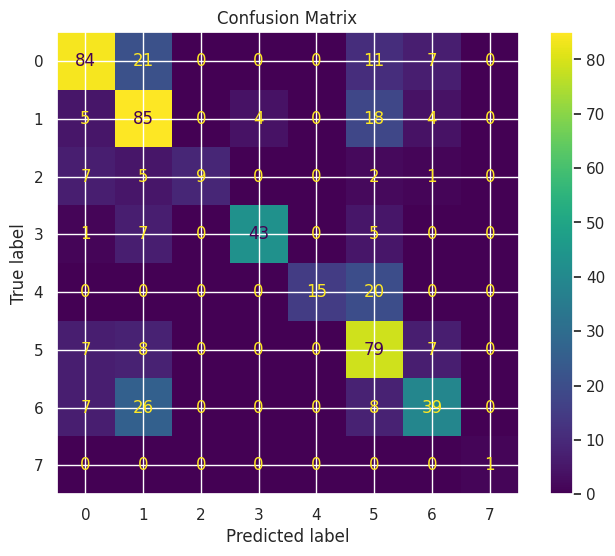


Executando modelo: MLP_depth_2layers | Experimento: HeavyMixed

Treinando modelo: MLPClassifier(hidden_layer_sizes=(30, 30), max_iter=500, random_state=42)


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Tempo de treino: 2.6716 segundos
Tempo de treino: 0.0014 segundos

Métricas Hold-Out:
Acurácia: 0.8470
Precisão: 0.8665
Recall: 0.8470
F1-score: 0.8432
Taxa de erro: 0.1530
Cohen Kappa: 0.8124
Tempo de treinamento: 2.6716 seg
Tempo de inferência: 0.0014 seg
Matriz de Confusão:
[[119   3   0   0   0   1   0   0]
 [  3  95   0   0   0  18   0   0]
 [  9   3  12   0   0   0   0   0]
 [  0   6   0  46   1   3   0   0]
 [  0   1   0   0  16  18   0   0]
 [  1   6   0   1   0  92   1   0]
 [  2   3   0   0   0   2  73   0]
 [  0   0   0   0   0   0   0   1]]


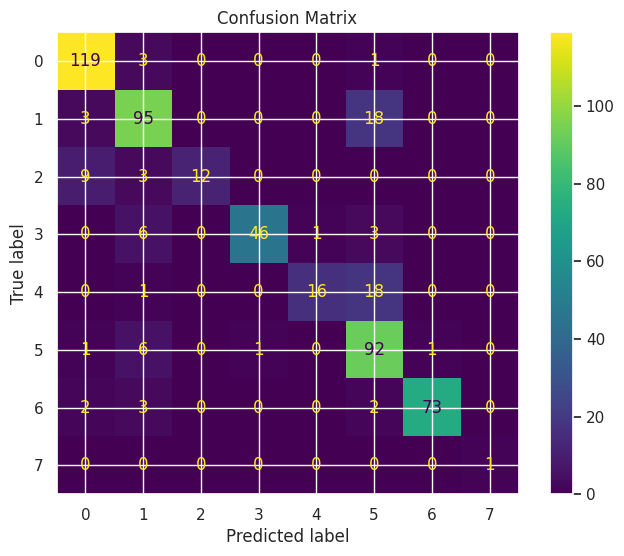


Executando modelo: MLP_depth_3layers | Experimento: HeavyMixed

Treinando modelo: MLPClassifier(hidden_layer_sizes=(30, 30, 30), max_iter=500, random_state=42)


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Tempo de treino: 3.4712 segundos
Tempo de treino: 0.0013 segundos

Métricas Hold-Out:
Acurácia: 0.9515
Precisão: 0.9528
Recall: 0.9515
F1-score: 0.9511
Taxa de erro: 0.0485
Cohen Kappa: 0.9411
Tempo de treinamento: 3.4712 seg
Tempo de inferência: 0.0013 seg
Matriz de Confusão:
[[120   2   0   0   0   1   0   0]
 [  0 110   0   1   2   3   0   0]
 [  5   0  19   0   0   0   0   0]
 [  0   2   0  49   0   5   0   0]
 [  0   2   0   0  33   0   0   0]
 [  0   3   0   0   0  98   0   0]
 [  0   0   0   0   0   0  80   0]
 [  0   0   0   0   0   0   0   1]]


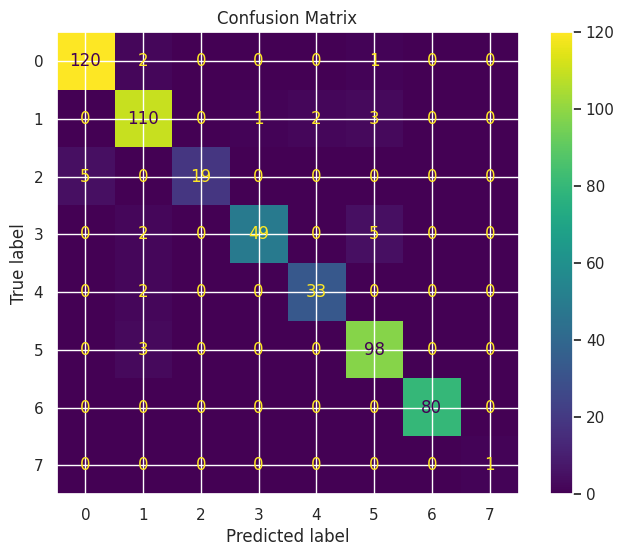


================ FIM DO PROCESSO ================



In [39]:
#bloco a arquitetura
from sklearn.neural_network import MLPClassifier

# =========================
# BASELINE FIXO
# =========================
baseline_params = dict(
    activation='relu',
    solver='adam',
    alpha=0.0001,
    learning_rate_init=0.001,
    early_stopping=False,
    random_state=42,
    max_iter=500
)

# =========================
# BLOCO A — PROFUNDIDADE
# =========================
architectures = [
    (30,),              # 1 camada
    (30, 30),           # 2 camadas
    (30, 30, 30)        # 3 camadas
]

models = {}

for arch in architectures:

    params = baseline_params.copy()
    params["hidden_layer_sizes"] = arch

    model_name = f"MLP_depth_{len(arch)}layers"

    models[model_name] = MLPClassifier(**params)

# Rodar no seu pipeline existente
classify(dungeon_frame, models, verbose=True)

In [39]:
#

# random_state - variar
# diminuir o neruosni no hidden
# ir aumentando l2
# teste com early stop
# com relu
# com tanh
# com adam
# sgd momentum
# learning rate
# gap de nerlaizao calcular
# difernets semsntes
# conferir valdicao cruzaa



1º Corrigir o augmentation, apenas o 6x (ok)

2º Corrigit o os, que da problema no classification (ok)

3º Download e mandar pro git (ok)

4º Corrigir ordem do split e augmenatnio (naomudar codigo inteiro, eu vou fazer o pt se mosrou incpometente ( vi no codigo deles, no artigo e eles fazem assim, vou manter a principi) - ok - conferir com o leo

5ºquando fucnionar, salvar - ok

6º hiperparametros - na mão (pedir ajuda pra fazer listinnha dos parametros mandados)

7º mandar o grid eoutro metodo la

8º ver se todos os casos ok

9º ver se nao esqueci algo (ex: tenho que add o gap)

10º ok? mandar pro git e ir pros proximos metodos

In [40]:
#entao, uma duvida, se eu pego por exemplo o melhor do bloco a e o melhor do bloco b seria a melhora combincao teorimcaten?